# 03 - Estensione ad altri pazienti virtuali (adult#001, #002, #003)

**Obiettivo.** Ripetere il confronto su altri pazienti virtuali con le stesse condizioni del notebook 02 (stessi guadagni
e parametri, pasto non annunciato alle 12:00, stesso seme). I controllori **non** vengono ritarati sul singolo paziente:
cambiano solo le grandezze che dipendono dal basale del paziente (limiti dell'integrale e tetto IOB).

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
import aid_sim as A, notebook_utils as U
pd.set_option("display.width", 220); pd.set_option("display.max_colwidth", 110)
SEED = 1                                  # seme del rumore del sensore (uguale per tutti i controllori)
COL = {"PID senza AW": "tab:gray", "PID": "tab:red", "PID cons.": "tab:orange",
       "PID+PLGS": "tab:green", "PID+IOB": "tab:purple", "PID+IOB+PLGS": "tab:blue"}
print("Versioni delle librerie usate:"); display(U.library_versions())

Versioni delle librerie usate:


,Pacchetto,Versione
0,Python,3.13.16
1,simglucose,0.2.11
2,numpy,2.4.4
3,scipy,1.17.1
4,pandas,3.0.2
5,matplotlib,3.10.8


In [2]:
def finestra(df):
    """Solo la finestra di analisi (08:00-24:00): l'assestamento 00:00-08:00 non entra né nei grafici né nelle metriche."""
    return df[df.t_h >= A.WARMUP_H]

def decora(ax, meal_h=A.MEAL_CLOCK_H, banda=True):
    """Linea del pasto e griglia; banda 70-180 mg/dL solo sui pannelli di glicemia."""
    if banda:
        ax.axhspan(70, 180, color="green", alpha=0.12)
    ax.axvline(meal_h, color="k", ls=":", lw=1.2); ax.grid(ls=":", alpha=0.5)

def tabella(risultati, chiavi):
    """risultati: dict {chiave: DataFrame}; chiavi: nomi delle colonne-indice per la tabella."""
    rows = []
    for k, df in risultati.items():
        k = k if isinstance(k, tuple) else (k,)
        rows.append({**dict(zip(chiavi, k)), **{m: round(float(v), 1) for m, v in A.metrics(df).items()}})
    return pd.DataFrame(rows)

## 1. Configurazione
### 1.1 Pazienti (parametri di simglucose)

In [3]:
import os, simglucose
PAZ = ["adult#001", "adult#002", "adult#003"]
q = pd.read_csv(os.path.join(os.path.dirname(simglucose.__file__), "params", "Quest.csv")).set_index("Name")
rows = []
for p in PAZ:
    ic = U.initial_conditions(p, SEED)
    rows.append({"Paziente": p, "BW [kg]": round(ic["BW"], 1), "Gb [mg/dL]": round(ic["Gb"], 1), "u_b [U/h]": round(ic["ub"] * 60, 2),
                 "CR [g/U]": q.loc[p, "CR"], "CF [mg/dL/U]": round(q.loc[p, "CF"], 1), "TDI [U/die]": round(q.loc[p, "TDI"], 1),
                 "kabs [1/min]": round(ic["kabs"], 4)})
display(pd.DataFrame(rows))

,Paziente,BW [kg],Gb [mg/dL],u_b [U/h],CR [g/U],CF [mg/dL/U],TDI [U/die],kabs [1/min]
0,adult#001,102.3,138.6,1.27,10,8.8,50.4,0.0891
1,adult#002,111.1,136.4,1.37,8,9.2,57.9,0.0214
2,adult#003,81.6,147.1,1.43,9,17.9,56.4,0.1697


### 1.2 Scenario e controllori

In [4]:
display(U.scenario_table("adult#001", "0, 60 o 90", SEED).iloc[6:])
NOMI = ["PID senza AW", "PID", "PID cons.", "PID+IOB+PLGS"]
for p in PAZ:
    ub_p = U.initial_conditions(p, SEED)["ub"]
    t = U.controller_table(A.CFG["PID+IOB+PLGS"], ub_p).set_index("Parametro").loc[["I_min, I_max (derivati)", "Ki*I_min, Ki*I_max", "iob_max (derivato)"]]
    print(p, "- grandezze che dipendono dal basale (PID+IOB+PLGS):"); display(t)

,Voce,Valore,Unita'
6,Seme casuale del sensore,1,-
7,Inizio simulazione,00:00 del giorno precedente (24 h prima),ora del giorno
8,Assestamento escluso dalle metriche,giorno precedente + 00:00-08:00 (32 h),-
9,Finestra di analisi,08:00-24:00,ora del giorno
10,Passo di campionamento dt,3.0,min
11,Passi totali / nella finestra,960 / 320,-
12,Glicemia plasmatica iniziale (inizio simulazione),138.6,mg/dL
13,Misura CGM iniziale (inizio simulazione),152.0,mg/dL
14,"Stati iniziali stimatore IOB (S1, S2)","0.0, 0.0",U
15,Orario del pasto,12:00,ora del giorno


adult#001 - grandezze che dipendono dal basale (PID+IOB+PLGS):


,Valore,Unita',Significato
Parametro,,,
"I_min, I_max (derivati)",-17602 ; 70409,mg*min/dL,Limiti effettivi dell'integrale dell'errore
"Ki*I_min, Ki*I_max",-0.32 ; 1.27,U/h,Contributo minimo e massimo dell'azione integrale
iob_max (derivato),0.95,U,Tetto IOB effettivo (attivo solo se use_iob=True)


adult#002 - grandezze che dipendono dal basale (PID+IOB+PLGS):


,Valore,Unita',Significato
Parametro,,,
"I_min, I_max (derivati)",-19021 ; 76085,mg*min/dL,Limiti effettivi dell'integrale dell'errore
"Ki*I_min, Ki*I_max",-0.34 ; 1.37,U/h,Contributo minimo e massimo dell'azione integrale
iob_max (derivato),1.03,U,Tetto IOB effettivo (attivo solo se use_iob=True)


adult#003 - grandezze che dipendono dal basale (PID+IOB+PLGS):


,Valore,Unita',Significato
Parametro,,,
"I_min, I_max (derivati)",-19796 ; 79184,mg*min/dL,Limiti effettivi dell'integrale dell'errore
"Ki*I_min, Ki*I_max",-0.36 ; 1.43,U/h,Contributo minimo e massimo dell'azione integrale
iob_max (derivato),1.07,U,Tetto IOB effettivo (attivo solo se use_iob=True)


### Unità di misura delle variabili salvate
| Variabile | Unità | Significato |
|---|---|---|
| `t_h` | h | ora del giorno di analisi (la simulazione parte alle 00:00 del giorno precedente, `t_h` = -24) |
| `CGM` | mg/dL | misura del sensore, con rumore: è l'unica grandezza vista dal controllore |
| `BG` | mg/dL | glicemia plasmatica del modello UVa/Padova (Gp/Vg), usata per le metriche |
| `Gsub` | mg/dL | glicemia sottocutanea senza rumore (`info['bg']` di simglucose) |
| `Insulin_Uh` | U/h | velocità di infusione comandata |
| `IOB` | U | insulina attiva netta stimata dal controllore (eccesso rispetto al basale) |
| `IOB_vero` | U | insulina sottocutanea netta del modello (Isc1 + Isc2 meno l'equilibrio basale) |
| `Vincolo` | - | vincolo attivo nel passo: `iob`, `plgs`, `sat_alta`, `sat_bassa` o vuoto |

Metriche: TIR, TAR, TBR in % del tempo nella finestra 08:00-24:00; `TIR_post6h` nelle 6 h dopo il pasto;
`TBR_tardivo` dalle 3 h dopo il pasto alle 24:00; picco e nadir in mg/dL; `insulina_tot` in U nella finestra.

## 2. Verifica a digiuno e pasti da 60 e 90 g

In [5]:
CARICHI = [0.0, 60.0, 90.0]
R = {(p, int(c), n): A.simulate(p, c, A.CFG[n], seed=SEED)[0] for p in PAZ for c in CARICHI for n in NOMI}
print(len(R), "simulazioni completate")

36 simulazioni completate


## 3. Grafici (60 g): glicemia e IOB per paziente

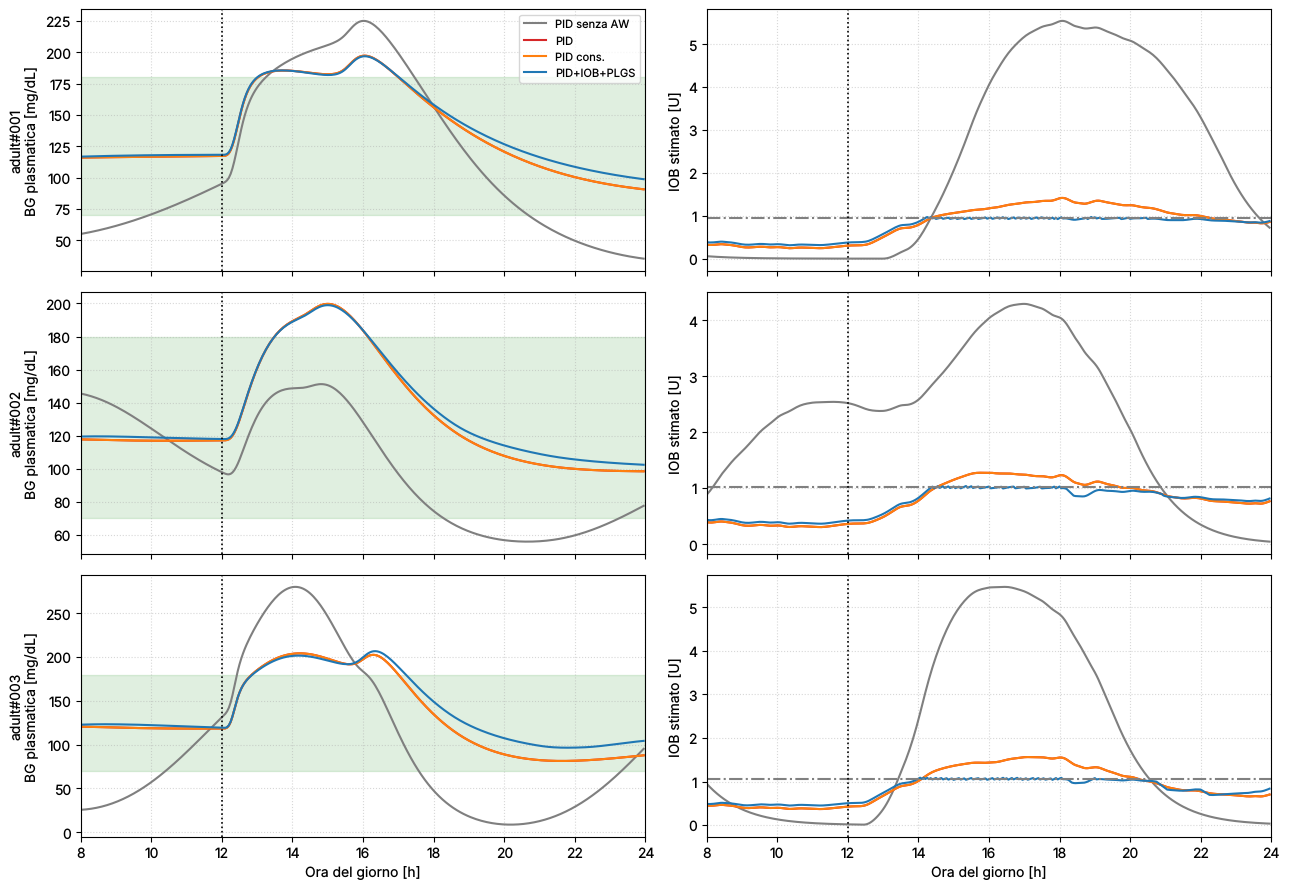

In [6]:
fig, ax = plt.subplots(3, 2, figsize=(13, 9), sharex=True)
for i, p in enumerate(PAZ):
    ub_p = U.initial_conditions(p, SEED)["ub"]
    for n in NOMI:
        d = finestra(R[(p, 60, n)])
        ax[i, 0].plot(d.t_h, d.BG, color=COL[n], label=n); ax[i, 1].plot(d.t_h, d.IOB, color=COL[n])
    ax[i, 1].axhline(A.IOB_ALPHA * ub_p * 60, color="gray", ls="-.")
    decora(ax[i, 0]); decora(ax[i, 1], banda=False)
    ax[i, 0].set_ylabel(f"{p}\nBG plasmatica [mg/dL]"); ax[i, 1].set_ylabel("IOB stimato [U]")
ax[0, 0].legend(fontsize=8); ax[2, 0].set_xlabel("Ora del giorno [h]"); ax[2, 1].set_xlabel("Ora del giorno [h]")
ax[2, 0].set_xlim(A.WARMUP_H, A.ANALYSIS_END_H); plt.tight_layout(); plt.show()

## 4. Indicatori clinici

In [7]:
T = tabella(R, ["Paziente", "CHO [g]", "Controllore"])
for c in [0, 60, 90]:
    print(f"Pasto da {c} g:" if c else "A digiuno (0 g):")
    display(T[T["CHO [g]"] == c].drop(columns="CHO [g]").reset_index(drop=True))

A digiuno (0 g):


,Paziente,Controllore,TIR,TAR,TAR>250,TBR,TBR<54,TBR_tardivo,TIR_post6h,picco,nadir,insulina_tot,IAE,IAE_post6h,IAE_range,t_rientro,n_commut,n_sosp,TV_u,std_u
0,adult#001,PID senza AW,87.8,0.0,0.0,12.2,0.0,0.0,100.0,160.9,55.2,32.8,474.3,124.0,16.2,0.0,0.0,0.0,9.4,1.6
1,adult#001,PID,100.0,0.0,0.0,0.0,0.0,0.0,100.0,118.1,116.1,23.3,40.3,13.6,0.0,0.0,0.0,0.0,8.2,0.1
2,adult#001,PID cons.,100.0,0.0,0.0,0.0,0.0,0.0,100.0,118.1,116.1,23.3,40.3,13.6,0.0,0.0,0.0,0.0,8.2,0.1
3,adult#001,PID+IOB+PLGS,100.0,0.0,0.0,0.0,0.0,0.0,100.0,118.8,116.8,23.5,29.7,11.7,0.0,0.0,4.0,2.0,12.9,0.3
4,adult#002,PID senza AW,100.0,0.0,0.0,0.0,0.0,0.0,100.0,145.5,83.7,28.3,308.9,186.6,0.0,0.0,0.0,0.0,9.9,0.9
5,adult#002,PID,100.0,0.0,0.0,0.0,0.0,0.0,100.0,117.8,116.2,25.4,49.0,18.7,0.0,0.0,0.0,0.0,8.2,0.1
6,adult#002,PID cons.,100.0,0.0,0.0,0.0,0.0,0.0,100.0,117.8,116.2,25.4,49.0,18.7,0.0,0.0,0.0,0.0,8.2,0.1
7,adult#002,PID+IOB+PLGS,100.0,0.0,0.0,0.0,0.0,0.0,100.0,119.6,116.7,25.4,25.4,12.4,0.0,0.0,4.0,2.0,13.4,0.3
8,adult#003,PID senza AW,42.5,8.4,0.0,49.1,39.4,60.0,71.7,187.0,23.3,28.2,928.1,250.2,245.8,11.0,0.0,0.0,11.0,1.5
9,adult#003,PID,100.0,0.0,0.0,0.0,0.0,0.0,100.0,120.6,115.8,26.9,37.0,15.5,0.0,0.0,0.0,0.0,8.2,0.1


Pasto da 60 g:


,Paziente,Controllore,TIR,TAR,TAR>250,TBR,TBR<54,TBR_tardivo,TIR_post6h,picco,nadir,insulina_tot,IAE,IAE_post6h,IAE_range,t_rientro,n_commut,n_sosp,TV_u,std_u
0,adult#001,PID senza AW,40.6,26.6,0.0,32.8,14.4,36.7,29.2,225.0,35.5,38.4,913.4,420.0,189.2,NaN,0.0,0.0,13.7,1.8
1,adult#001,PID,75.0,25.0,0.0,0.0,0.0,0.0,33.3,197.3,90.8,28.7,460.5,342.1,27.3,5.0,0.0,0.0,8.5,0.3
2,adult#001,PID cons.,75.0,25.0,0.0,0.0,0.0,0.0,33.3,197.3,90.8,28.7,460.5,342.1,27.3,5.0,0.0,0.0,8.5,0.3
3,adult#001,PID+IOB+PLGS,74.7,25.3,0.0,0.0,0.0,0.0,32.5,196.8,98.8,27.7,438.1,342.8,26.4,5.0,62.0,0.0,56.8,0.3
4,adult#002,PID senza AW,69.1,0.0,0.0,30.9,0.0,55.0,100.0,151.2,56.0,40.3,530.8,133.4,47.0,11.2,0.0,0.0,10.3,1.2
5,adult#002,PID,83.4,16.6,0.0,0.0,0.0,0.0,55.8,199.7,98.5,29.8,394.2,294.5,32.0,4.1,0.0,0.0,8.4,0.2
6,adult#002,PID cons.,83.4,16.6,0.0,0.0,0.0,0.0,55.8,199.7,98.5,29.8,394.2,294.5,32.0,4.1,0.0,0.0,8.4,0.2
7,adult#002,PID+IOB+PLGS,83.4,16.6,0.0,0.0,0.0,0.0,55.8,198.9,102.5,29.1,366.7,297.7,30.8,4.1,36.0,2.0,40.1,0.3
8,adult#003,PID senza AW,25.6,23.1,10.9,51.2,43.1,63.9,31.7,280.1,8.7,32.8,1282.5,526.6,536.8,11.4,0.0,0.0,12.5,1.9
9,adult#003,PID,73.8,26.2,0.0,0.0,0.0,0.0,30.0,204.2,81.4,31.7,559.5,379.0,69.6,5.0,0.0,0.0,8.6,0.3


Pasto da 90 g:


,Paziente,Controllore,TIR,TAR,TAR>250,TBR,TBR<54,TBR_tardivo,TIR_post6h,picco,nadir,insulina_tot,IAE,IAE_post6h,IAE_range,t_rientro,n_commut,n_sosp,TV_u,std_u
0,adult#001,PID senza AW,34.4,30.9,5.6,34.7,17.2,40.0,17.5,261.6,30.6,39.9,1105.1,580.4,357.9,NaN,0.0,0.0,14.0,1.9
1,adult#001,PID,67.5,32.5,0.0,0.0,0.0,0.0,13.3,236.8,79.6,31.4,680.8,515.3,184.4,5.9,0.0,0.0,8.8,0.4
2,adult#001,PID cons.,67.5,32.5,0.0,0.0,0.0,0.0,13.3,236.8,83.4,30.3,672.9,515.3,184.4,5.9,0.0,0.0,8.8,0.4
3,adult#001,PID+IOB+PLGS,65.3,34.7,0.0,0.0,0.0,0.0,11.7,238.6,101.6,28.0,660.2,526.5,196.1,6.2,128.0,0.0,127.2,0.4
4,adult#002,PID senza AW,55.0,8.8,0.0,36.2,17.8,64.4,76.7,185.7,49.7,43.6,662.5,226.9,86.4,NaN,0.0,0.0,11.2,1.4
5,adult#002,PID,75.6,24.4,0.0,0.0,0.0,0.0,35.0,241.1,90.9,31.9,579.5,447.0,151.3,5.0,0.0,0.0,8.6,0.3
6,adult#002,PID cons.,75.6,24.4,0.0,0.0,0.0,0.0,35.0,241.1,91.8,31.7,577.2,447.0,151.3,5.0,0.0,0.0,8.7,0.3
7,adult#002,PID+IOB+PLGS,74.1,25.9,0.0,0.0,0.0,0.0,30.8,240.9,99.6,29.8,556.3,467.1,159.4,5.2,78.0,1.0,87.7,0.3
8,adult#003,PID senza AW,22.5,25.6,15.9,51.9,44.1,65.0,26.7,325.8,4.3,34.6,1451.1,667.2,692.1,11.5,0.0,0.0,13.2,2.0
9,adult#003,PID,57.8,30.6,0.0,11.6,0.0,20.6,18.3,247.0,67.8,34.0,807.4,562.8,240.4,10.6,0.0,0.0,9.0,0.4


## 5. Lettura dei risultati (calcolata dalla tabella)

In [8]:
for p in PAZ:
    for c in [60, 90]:
        a = T[(T.Paziente == p) & (T["CHO [g]"] == c) & (T.Controllore == "PID")].iloc[0]
        b = T[(T.Paziente == p) & (T["CHO [g]"] == c) & (T.Controllore == "PID+IOB+PLGS")].iloc[0]
        print(f"{p} {c} g: TBR {a.TBR:4.1f} -> {b.TBR:4.1f} % | TBR<54 {a['TBR<54']:4.1f} -> {b['TBR<54']:4.1f} % | "
              f"TIR {a.TIR:5.1f} -> {b.TIR:5.1f} % | picco {a.picco:4.0f} -> {b.picco:4.0f} mg/dL")

adult#001 60 g: TBR  0.0 ->  0.0 % | TBR<54  0.0 ->  0.0 % | TIR  75.0 ->  74.7 % | picco  197 ->  197 mg/dL
adult#001 90 g: TBR  0.0 ->  0.0 % | TBR<54  0.0 ->  0.0 % | TIR  67.5 ->  65.3 % | picco  237 ->  239 mg/dL
adult#002 60 g: TBR  0.0 ->  0.0 % | TBR<54  0.0 ->  0.0 % | TIR  83.4 ->  83.4 % | picco  200 ->  199 mg/dL
adult#002 90 g: TBR  0.0 ->  0.0 % | TBR<54  0.0 ->  0.0 % | TIR  75.6 ->  74.1 % | picco  241 ->  241 mg/dL
adult#003 60 g: TBR  0.0 ->  0.0 % | TBR<54  0.0 ->  0.0 % | TIR  73.8 ->  72.8 % | picco  204 ->  207 mg/dL
adult#003 90 g: TBR 11.6 ->  0.0 % | TBR<54  0.0 ->  0.0 % | TIR  57.8 ->  65.9 % | picco  247 ->  261 mg/dL


**Limiti.** Guadagni e soglie non sono ritarati sul singolo paziente e non sono stati ottimizzati: i risultati mostrano il
comportamento con parametri fissi, non il miglior risultato ottenibile per ciascun soggetto.